In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf


In [2]:
df = pd.read_csv('train.csv')

In [3]:
df.head(10)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0


In [4]:
df.shape

(159571, 8)

In [5]:
df.dtypes

id                 str
comment_text       str
toxic            int64
severe_toxic     int64
obscene          int64
threat           int64
insult           int64
identity_hate    int64
dtype: object

In [6]:
df.isnull().sum()

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns.tolist()

['id',
 'comment_text',
 'toxic',
 'severe_toxic',
 'obscene',
 'threat',
 'insult',
 'identity_hate']

In [9]:
print("Duplicate comments:", df['comment_text'].duplicated().sum())

Duplicate comments: 0


In [10]:
def get_label(row):
    if row['identity_hate'] == 1:
        return 'Identity_Attack'
    elif row['severe_toxic'] == 1:
        return 'Severe_Toxic'
    elif row['threat'] == 1:
        return 'Threat'
    elif row['toxic'] == 1 or row['obscene'] == 1 or row['insult'] == 1:
        return 'Toxic'
    else:
        return 'Clean'

df['Toxicity_Label'] = df.apply(get_label, axis=1)

print(df['Toxicity_Label'].value_counts())

Toxicity_Label
Clean              143346
Toxic               13238
Identity_Attack      1405
Severe_Toxic         1282
Threat                300
Name: count, dtype: int64


In [11]:
import numpy as np

conditions = [
    df['identity_hate'] == 1,
    df['severe_toxic'] == 1,
    df['threat'] == 1,
    (df['toxic'] == 1) | (df['obscene'] == 1) | (df['insult'] == 1)
]

labels = ['Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']

df['Toxicity_Label'] = np.select(conditions, labels, default='Clean')

print(df['Toxicity_Label'].value_counts())

Toxicity_Label
Clean              143346
Toxic               13238
Identity_Attack      1405
Severe_Toxic         1282
Threat                300
Name: count, dtype: int64


In [12]:
import sys
!{sys.executable} -m pip install emoji

In [13]:
import pandas as pd
import re                      # Regular Expressions ke liye
import string                  # String operations ke liye
import emoji                   # Emojis handle karne ke liye (agar install nahi hai to: pip install emoji)

In [14]:
def clean_comment(text):
    text = str(text).lower()                         # lowercase
    text = re.sub(r'<.*?>', '', text)               # remove HTML tags
    text = re.sub(r'http\S+|www\S+', '', text)      # remove links
    text = re.sub(r'[^a-z\s]', '', text)             # remove numbers, punctuation, emojis, special characters
    text = re.sub(r'\s+', ' ', text).strip()         # remove extra whitespace
    return text

df['comment_text'] = df['comment_text'].apply(clean_comment)

In [15]:
df['comment_text'].head()

0    explanation why the edits made under my userna...
1    daww he matches this background colour im seem...
2    hey man im really not trying to edit war its j...
3    more i cant make any real suggestions on impro...
4    you sir are my hero any chance you remember wh...
Name: comment_text, dtype: str

In [16]:
# Check karein ke koi uppercase, punctuation, ya numbers bache?
print("Any uppercase?", df['comment_text'].str.contains(r'[A-Z]', regex=True).any())
print("Any digits?", df['comment_text'].str.contains(r'\d', regex=True).any())
print("Any punctuation?", df['comment_text'].str.contains(r'[^\w\s]', regex=True).any())

Any uppercase? False
Any digits? False
Any punctuation? False


In [17]:
print("Empty comments:", (df['comment_text'].str.strip() == '').sum())
print("Duplicates after cleaning:", df['comment_text'].duplicated().sum())

Empty comments: 25
Duplicates after cleaning: 1354


In [18]:
df = df[df['comment_text'].str.strip() != '']
df = df.drop_duplicates(subset='comment_text', keep='first')

print("New shape:", df.shape)
print(df['Toxicity_Label'].value_counts())

New shape: (158216, 9)
Toxicity_Label
Clean              142129
Toxic               13134
Identity_Attack      1391
Severe_Toxic         1271
Threat                291
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split   # data ho tarin or test 2 hiso main bantna
from tensorflow.keras.preprocessing.text import Tokenizer    
from tensorflow.keras.preprocessing.sequence import pad_sequences   # for 	Sab sequences ki same length
from sklearn.preprocessing import LabelEncoder

In [20]:
# Features aur Target alag karein
X = df['comment_text']      # Features (text)
y = df['Toxicity_Label']              # Target (diff classes)

In [21]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (158216,)
y shape: (158216,)


In [22]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("Classes:", list(label_encoder.classes_))
print("Train:", X_train.shape, "Test:", X_test.shape)

Classes: ['Clean', 'Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']
Train: (126572,) Test: (31644,)


In [23]:
print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")

Training samples: 126572
Testing samples:  31644


In [24]:
max_words = 10000
max_length = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train) #  ZAROORI: SIRF X_train pe fit karna h ab

vocab_size = max_words
print("Vocab size:", vocab_size)

Vocab size: 10000


In [25]:
# Training aur test dono ko sequences mein convert karein
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_length, padding='post', truncating='post') # End mein zeros add karein #Extra words end se hatao
X_test_pad = pad_sequences(X_test_seq, maxlen=max_length, padding='post', truncating='post')

print("X_train_pad:", X_train_pad.shape)
print("X_test_pad:", X_test_pad.shape)

X_train_pad: (126572, 100)
X_test_pad: (31644, 100)


In [26]:
lengths = [len(s) for s in X_train_seq]
print("Median length:", np.median(lengths))
print("Comments longer than 100:", np.mean(np.array(lengths) > 100) * 100, "%")

Median length: 35.0
Comments longer than 100: 17.128590841576337 %


In [27]:
from sklearn.utils import class_weight

In [49]:
class_weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = {i: w ** 0.5 for i, w in enumerate(class_weights)}
print(class_weights_dict)

{0: np.float64(0.47184544526725153), 1: np.float64(4.769097891531655), 2: np.float64(4.98911302446585), 3: np.float64(10.423314902766382), 4: np.float64(1.5521884696770254)}


In [50]:
from sklearn.preprocessing import LabelEncoder   #Text labels ko numbers mein
from tensorflow.keras.models import Sequential   # Model banane ke liye
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D    # Layers
from tensorflow.keras.callbacks import EarlyStopping  #Training rok de agar improvement na ho

In [51]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64),
    SpatialDropout1D(0.3),
    LSTM(64, dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

model.build(input_shape=(None, max_length))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 100, 64)             │         640,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d_1                  │ (None, 100, 64)             │               0 │
│ (SpatialDropout1D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 677,509 (2.58 MB)

 Trainable params: 677,509 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")
print(f"Optimizer: Adam")
print(f"Loss: sparse_categorical_crossentropy")
print(f"Metrics: accuracy")

Model compiled successfully!
Optimizer: Adam
Loss: sparse_categorical_crossentropy
Metrics: accuracy


In [53]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train_pad, y_train,
    batch_size=32,
    epochs=10,
    validation_split=0.2,
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 309s 95ms/step - accuracy: 0.8979 - loss: 0.6865 - val_accuracy: 0.8948 - val_loss: 0.5353
Epoch 2/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 341s 108ms/step - accuracy: 0.9154 - loss: 0.4437 - val_accuracy: 0.9291 - val_loss: 0.2071
Epoch 3/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 337s 106ms/step - accuracy: 0.9296 - loss: 0.3478 - val_accuracy: 0.9342 - val_loss: 0.2030
Epoch 4/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 340s 107ms/step - accuracy: 0.9329 - loss: 0.3235 - val_accuracy: 0.9259 - val_loss: 0.2046
Epoch 5/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 335s 106ms/step - accuracy: 0.9349 - loss: 0.2995 - val_accuracy: 0.9215 - val_loss: 0.2098
Epoch 6/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 317s 100ms/step - accuracy: 0.9394 - loss: 0.2750 - val_accuracy: 0.9316 - val_loss: 0.2000
Epoch 7/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 281s 89ms/step - accuracy: 0.9402 - loss: 0.2529 - val_accuracy: 0.9259 - val_loss: 0.2039
Epoch 8/10
3165/3165 ━━━━━━━━━━━━━━━━━━━━ 307s 97ms/step - accur

In [54]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay


In [55]:
y_pred_prob = model.predict(X_test_pad, verbose=0)
y_pred = y_pred_prob.argmax(axis=1)

In [56]:
print("Predictions shape:", y_pred.shape)
print("First 10 predictions:", y_pred[:10])
print("First 10 actual:     ", y_test[:10])

Predictions shape: (31644,)
First 10 predictions: [0 0 0 0 0 0 0 0 4 0]
First 10 actual:      [0 0 0 0 0 0 0 0 0 0]


In [57]:
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, verbose=0)

In [58]:
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

Test Loss: 0.20183467864990234
Test Accuracy: 0.9274743795394897
Test Accuracy (%): 92.74743795394897


In [59]:
cm = confusion_matrix(y_test, y_pred)
class_names = list(label_encoder.classes_)

In [60]:
print(cm)
print(class_names)

[[27330     8     0    15  1074]
 [   17    72    67     8   114]
 [    0    43   111     2    98]
 [    9    13     0     7    29]
 [  505   115   157    21  1829]]
['Clean', 'Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']


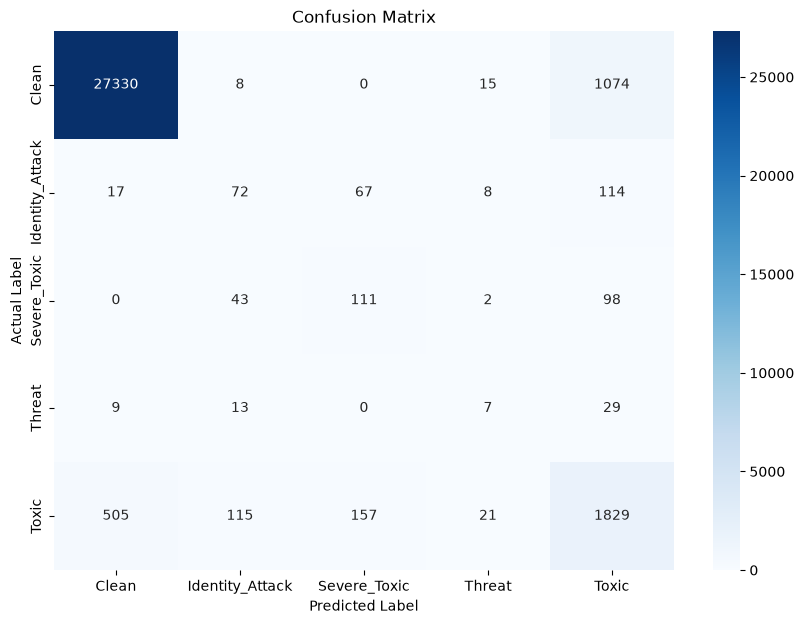

In [61]:
cm = confusion_matrix(y_test, y_pred)
class_names = list(label_encoder.classes_)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [62]:
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

                 precision    recall  f1-score   support

          Clean     0.9809    0.9614    0.9711     28427
Identity_Attack     0.2869    0.2590    0.2722       278
   Severe_Toxic     0.3313    0.4370    0.3769       254
         Threat     0.1321    0.1207    0.1261        58
          Toxic     0.5817    0.6962    0.6339      2627

       accuracy                         0.9275     31644
      macro avg     0.4626    0.4949    0.4760     31644
   weighted avg     0.9349    0.9275    0.9306     31644



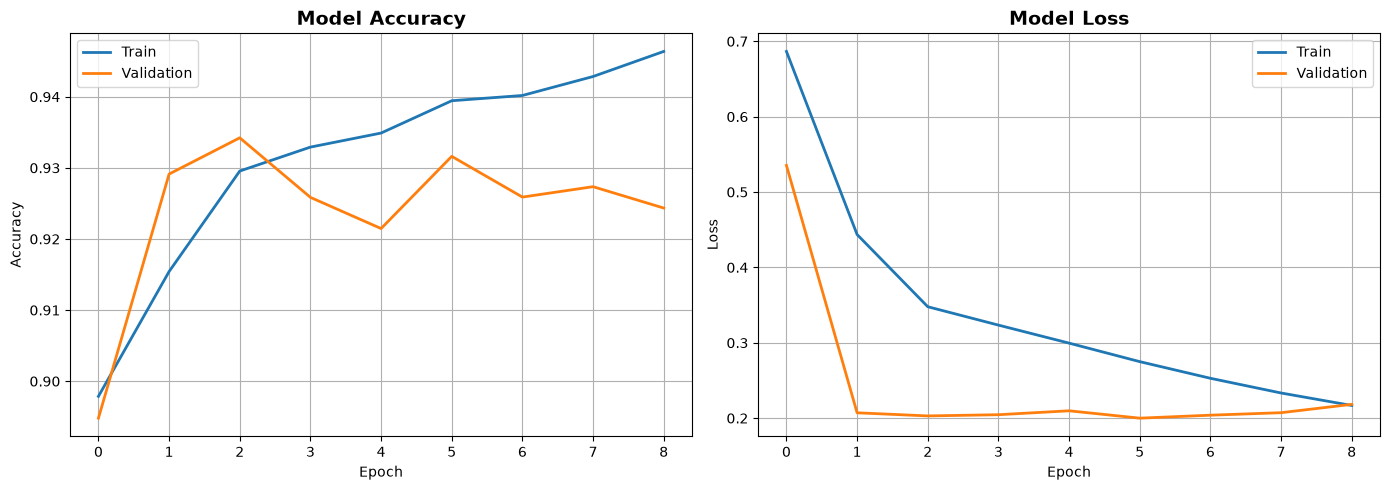

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation', linewidth=2)
axes[0].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['loss'], label='Train', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation', linewidth=2)
axes[1].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout() #graphs ke darmiyan spacing adjust karta hai taake labels aur titles ek doosre par na charhein.
plt.show()

In [64]:
user_input = input("Enter comment: ")
user_clean = clean_comment(user_input)
user_seq = tokenizer.texts_to_sequences([user_clean])
user_pad = pad_sequences(user_seq, maxlen=max_length, padding='post')
pred = model.predict(user_pad, verbose=0)
print("Predicted:", label_encoder.classes_[pred.argmax()])

Enter comment:  "i will kill you"


Predicted: Threat


In [65]:
def predict_comment(text):
    clean = clean_comment(text)
    seq = tokenizer.texts_to_sequences([clean])
    pad = pad_sequences(seq, maxlen=max_length, padding='post')
    probs = model.predict(pad, verbose=0)[0]
    top = probs.argmax()
    print(f"{text!r} -> {label_encoder.classes_[top]} ({probs[top]*100:.1f}%)")

tests = [
    "Thank you for fixing the references in this article",
    "I think this section needs more sources",
    "You are such an idiot, stop editing this page",
    "I will find you and hurt you",
    "i will kill you",
    "People like you should not be allowed on this site",
    "What a stupid and pathetic edit",
]

for t in tests:
    predict_comment(t)

'Thank you for fixing the references in this article' -> Clean (100.0%)
'I think this section needs more sources' -> Clean (99.9%)
'You are such an idiot, stop editing this page' -> Toxic (92.5%)
'I will find you and hurt you' -> Toxic (32.1%)
'i will kill you' -> Threat (30.0%)
'People like you should not be allowed on this site' -> Clean (58.9%)
'What a stupid and pathetic edit' -> Toxic (90.9%)
